In [ ]:
import pandas as pd
print('Ready')

Ready


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# **Pharmaceutical Sales Trend Analysis**

## **Business Objective**

The objective of this project is to analyze pharmaceutical sales data across multiple drug categories and identify patterns in sales performance over time.

The analysis focuses on:
- Identifying the highest-selling drug categories
- Examining yearly and monthly sales trends
- Investigating potential seasonal patterns in pharmaceutical demand
- Generating insights that could support inventory and sales planning

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving pharma_sales_data.csv to pharma_sales_data.csv


In [ ]:
df = pd.read_csv('pharma_sales_data.csv')

In [ ]:
df.head()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday
1,1/3/2014,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday
2,1/4/2014,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
3,1/5/2014,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday
4,1/6/2014,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday


In [ ]:
df.columns

Index(['datum', 'M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03',
       'R06', 'Year', 'Month', 'Hour', 'Weekday Name'],
      dtype='object')

In [ ]:
df.describe()

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour
count,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000
mean,5.033683,3.895830,3.880441,29.917095,8.853627,0.593522,5.512262,2.900198,2016.401235,6.344255,275.945869
std,2.737579,2.133337,2.384010,15.590966,5.605605,1.092988,6.428736,2.415816,1.665060,3.386954,1.970547
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2014.000000,1.000000,190.000000
25%,3.000000,2.340000,2.000000,19.000000,5.000000,0.000000,1.000000,1.000000,2015.000000,3.000000,276.000000
50%,4.990000,3.670000,3.500000,26.900000,8.000000,0.000000,4.000000,2.000000,2016.000000,6.000000,276.000000
75%,6.670000,5.138000,5.200000,38.300000,12.000000,1.000000,8.000000,4.000000,2018.000000,9.000000,276.000000
max,17.340000,14.463000,16.000000,161.000000,54.833333,9.000000,45.000000,15.000000,2019.000000,12.000000,276.000000


##**Dataset Understanding**

The dataset contains daily pharmaceutical sales records from 2014 to 2019. Each row represents a single day, while the drug category columns contain sales values for different pharmaceutical product groups.

The dataset includes eight drug categories (M01AB, M01AE, N02BA, N02BE, N05B, N05C, R03, and R06) along with date-related information such as year, month, hour, and weekday name.

These variables enable the analysis of sales performance across drug categories as well as the investigation of temporal trends, including yearly, monthly, and seasonal patterns in pharmaceutical demand.

In [ ]:
df.isnull().sum()

,0
datum,0
M01AB,0
M01AE,0
N02BA,0
N02BE,0
N05B,0
N05C,0
R03,0
R06,0
Year,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.dtypes

,0
datum,object
M01AB,float64
M01AE,float64
N02BA,float64
N02BE,float64
N05B,float64
N05C,float64
R03,float64
R06,float64
Year,int64


In [ ]:
df['datum']=pd.to_datetime(df['datum'])

In [ ]:
df['datum'].head()

,datum
0,2014-01-02
1,2014-01-03
2,2014-01-04
3,2014-01-05
4,2014-01-06


### **Findings**

- No missing values were identified in any column.
- No duplicate records were found.
- The date column was converted to datetime format.
- No negative sales values were observed.
- The dataset required minimal preprocessing.


## **Analysis 1: Sales by Drug Category**

In [ ]:
sales_col = ['M01AB',	'M01AE',	'N02BA',	'N02BE',	'N05B', 'N05C',	'R03',	'R06']
df[sales_col].sum().sort_values(ascending = False)

,0
N02BE,63005.402708
N05B,18645.737500
R03,11608.822917
M01AB,10600.937083
M01AE,8204.618646
N02BA,8172.209000
R06,6107.817500
N05C,1249.958333


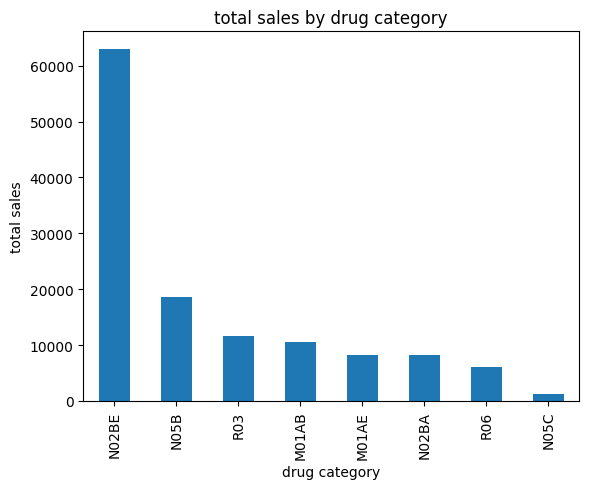

In [ ]:
df[sales_col].sum().sort_values(ascending = False).plot(kind = 'bar')
plt.title('total sales by drug category')
plt.xlabel('drug category')
plt.ylabel('total sales')
plt.show()


### **Findings**

- N02BE was the highest-selling drug category with total sales of approximately 63,005 units.
- N05C recorded the lowest sales among all drug categories.
- N02BE significantly outperformed all other categories, indicating that pharmaceutical demand was heavily concentrated in this category.

## **Analysis 2: Yearly Sales Trends**

In [ ]:
df['total_sales'] = df[sales_col].sum(axis = 1)
df.head()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name,total_sales
0,2014-01-02,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday,48.47
1,2014-01-03,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday,107.00
2,2014-01-04,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday,91.35
3,2014-01-05,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday,66.10
4,2014-01-06,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday,58.20


In [ ]:
df['total_sales'].groupby(df['datum'].dt.year).sum()


,total_sales
datum,
2014,20238.337687
2015,22752.358000
2016,25234.926000
2017,19399.365667
2018,22884.561000
2019,17085.955333


In [ ]:
df.groupby('Year').size()

,0
Year,
2014,364
2015,365
2016,366
2017,365
2018,365
2019,281


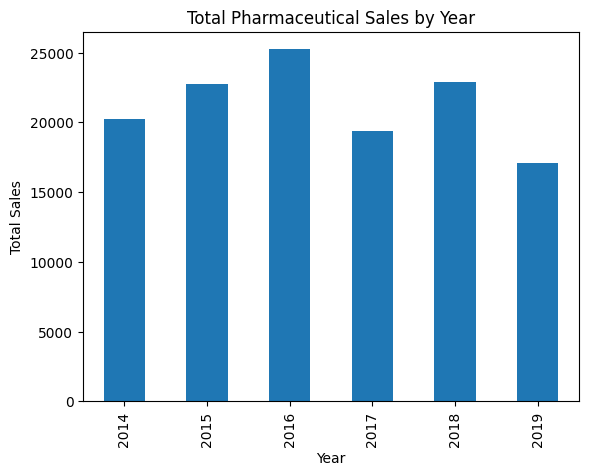

In [ ]:
df.groupby('Year')['total_sales'].sum().plot(kind='bar')

plt.title('Total Pharmaceutical Sales by Year')
plt.ylabel('Total Sales')
plt.show()

### **Findings**

- Annual sales fluctuated between 2014 and 2019.
- Sales increased between 2014 and 2016 before declining in 2017.
- The 2019 results should be interpreted cautiously because the dataset contains fewer observations for that year.

## **Analysis 3: Monthly Sales Trends**

In [ ]:
df.groupby('Month')['total_sales'].sum()

,total_sales
Month,
1,13970.691083
2,11604.568583
3,11363.605000
4,10248.718000
5,9925.967667
6,8992.861000
7,8758.503333
8,9037.611333
9,11000.856667


In [ ]:
df.groupby('Month')['total_sales'].mean()

,total_sales
Month,
1,75.517249
2,68.666086
3,61.094651
4,56.937322
5,53.365418
6,49.960339
7,47.088728
8,48.589308
9,61.115870


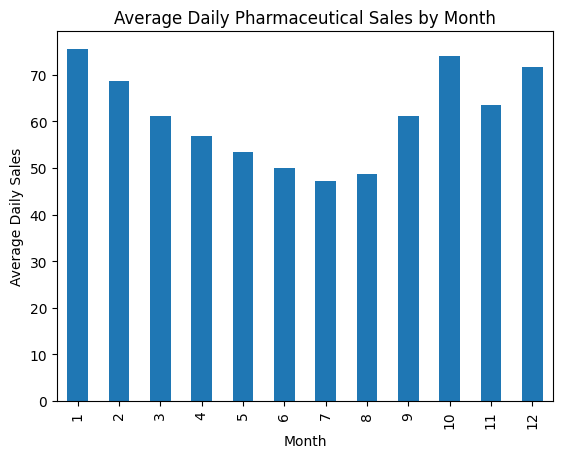

In [ ]:
df.groupby('Month')['total_sales'].mean().plot(kind='bar')

plt.title('Average Daily Pharmaceutical Sales by Month')
plt.xlabel('Month')
plt.ylabel('Average Daily Sales')
plt.show()

### **Findings**

- Average daily sales were highest in January, October, and December.
- Average daily sales were lowest during June, July, and August.
- Sales declined steadily during the first half of the year before recovering in later months.
- The observed pattern suggests a possible seasonal influence on pharmaceutical demand.
- Further investigation would be required to determine the underlying causes of this trend.

### **N02BE Monthly Trend Analysis**

In [ ]:
df.groupby('Month')['N02BE'].mean()

,N02BE
Month,
1,41.258870
2,36.138910
3,29.932785
4,25.711911
5,23.053656
6,20.634061
7,19.529382
8,20.568599
9,32.028533


In [ ]:
(df['N02BE'].sum()/df['total_sales'].sum())*100

np.float64(49.37901484574042)

### **Findings**

- N02BE was the highest-selling drug category in the dataset, recording approximately 63,005 units of sales during the study period.
- N02BE alone accounted for approximately 49.38% of total pharmaceutical sales.
- Since the dataset contains eight drug categories, an equal distribution of sales would imply a contribution of approximately 12.5% per category. N02BE therefore contributed nearly four times the share expected under an equal distribution scenario.
- The remaining seven drug categories collectively accounted for approximately 50.62% of total sales, indicating that N02BE alone generated nearly the same sales volume as all other categories combined.
- Monthly N02BE sales were highest in January and October and lowest during June and July.
- The monthly pattern observed for N02BE closely resembled the overall pharmaceutical sales trend, suggesting that N02BE is a major driver of the seasonality observed in the dataset.
- The strong concentration of sales within N02BE indicates that changes in demand for this category may have a disproportionate impact on overall pharmaceutical sales performance.

## **Analysis 4: Consistency of Monthly Sales Patterns Across Years**

In [ ]:
monthly_yearly = df.pivot_table(
    index = 'Month',
    columns = 'Year',
    values = 'total_sales',
    aggfunc = 'mean'
)
monthly_yearly

Year,2014,2015,2016,2017,2018,2019
Month,,,,,,
1,60.037000,69.604806,79.076645,87.083777,64.054871,92.747032
2,70.516786,65.411857,76.979310,51.695414,77.660643,69.435607
3,51.829677,62.873419,72.102226,44.414677,69.575710,65.772194
4,47.464167,57.462833,71.585767,44.726667,63.157667,57.226833
5,48.590419,53.050871,63.129710,44.176935,53.230000,58.014570
6,46.340167,55.807767,57.491033,43.564533,47.144967,49.413567
7,42.979677,49.130581,51.601269,40.359710,50.434806,48.026323
8,46.855484,53.535387,52.689946,42.013548,51.997000,44.444484
9,60.153133,55.978900,68.329233,55.361367,66.045800,60.826789


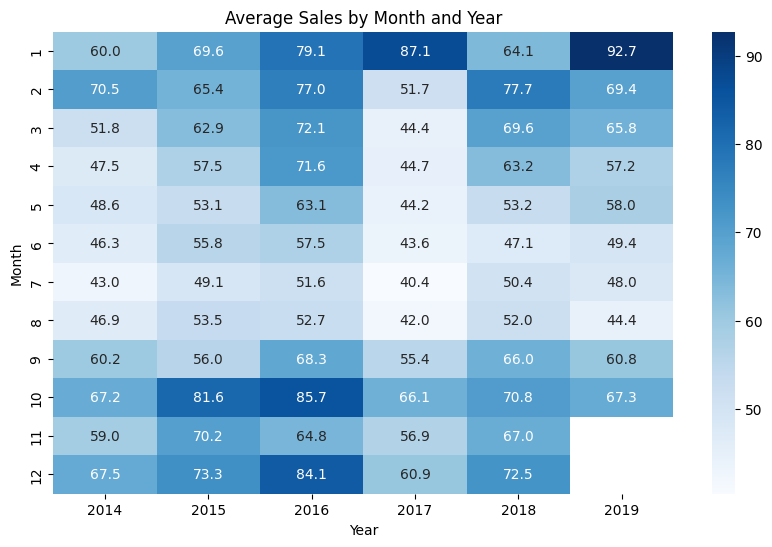

In [ ]:
plt.figure(figsize=(10,6))

sns.heatmap(
    monthly_yearly,
    cmap='Blues',
    annot=True,
    fmt='.1f'
)

plt.title('Average Sales by Month and Year')

plt.show()

### Findings

- The month-by-year heatmap reveals a consistent seasonal pattern in pharmaceutical sales across the six-year period (2014–2019).

- Average sales are generally highest during the beginning and end of the year, particularly in January, October, and December. January recorded the highest average monthly sales in multiple years, reaching 92.7 units in 2019 and 87.1 units in 2017.

- Sales levels tend to decline gradually from January through the middle of the year, with the lowest average sales consistently observed between June and August. July recorded some of the lowest values across all years, including 40.4 units in 2017 and 43.0 units in 2014.

- The recurring pattern of high sales in winter months and lower sales during mid-year suggests the presence of seasonality in pharmaceutical demand.

- Although the seasonal pattern remains broadly consistent, 2016 stands out as an unusually strong year. Average monthly sales exceeded those of most other years across nearly all months, with October 2016 recording 85.7 units and December 2016 reaching 84.1 units.

- The persistence of similar monthly patterns across multiple years indicates that the observed seasonality is unlikely to be the result of random variation. This strengthens confidence in the reliability of the trend and supports the use of historical sales patterns for forecasting purposes.

- Missing values for November and December 2019 are due to incomplete data availability for those months and do not materially affect the overall seasonal interpretation.

### **N02BE Monthly Trend Analysis**

In [ ]:
drug_cols = [
    'M01AB',
    'M01AE',
    'N02BA',
    'N02BE',
    'N05B',
    'N05C',
    'R03',
    'R06'
]

In [ ]:
monthly_drugs = df.groupby('Month')[drug_cols].mean()

monthly_drugs

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
Month,,,,,,,,
1,5.022336,4.367158,4.636329,41.258870,10.988919,0.790090,6.835980,1.617568
2,4.999527,4.660450,4.679024,36.138910,9.024803,0.563116,6.896943,1.703314
3,4.912097,3.891731,3.993844,29.932785,8.265591,0.623656,6.290323,3.184624
4,5.117944,3.590106,3.711944,25.711911,7.852222,0.477778,5.771528,4.703889
5,4.846183,3.649548,3.715806,23.053656,7.482796,0.607527,5.006944,5.002957
6,4.714778,3.567889,3.753944,20.634061,7.913889,0.588889,4.350000,4.436889
7,5.207921,3.774919,3.483333,19.529382,8.298925,0.478495,2.956989,3.358763
8,5.428333,3.624366,3.477151,20.568599,9.086022,0.612903,3.102151,2.689785
9,5.004889,3.969856,3.374167,32.028533,9.240556,0.522222,4.402315,2.573333


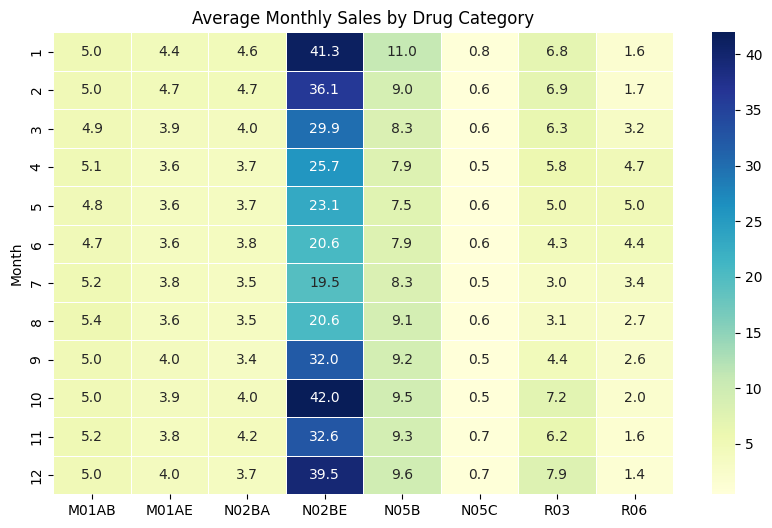

In [ ]:
plt.figure(figsize=(10,6))

sns.heatmap(
    monthly_drugs,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Average Monthly Sales by Drug Category')

plt.show()

### Findings

- Seasonal variation is not uniform across all drug categories.

- N02BE exhibits the strongest seasonal pattern, with average monthly sales ranging from 19.5 units in July to 42.0 units in October, representing a variation of more than 115%.

- N02BE contributes approximately 49.4% of total pharmaceutical sales and therefore appears to be the primary driver of the seasonal fluctuations observed in overall demand.

- Most other drug categories, including M01AB, M01AE, N02BA, and N05C, remain relatively stable throughout the year and show limited seasonal variation.

- N05B and R03 demonstrate mild seasonal patterns; however, their fluctuations are substantially smaller than those observed for N02BE.

- The concentration of seasonality within a single high-volume category suggests that inventory planning and forecasting efforts should focus primarily on N02BE products.

## **Key Business Insights**

- N02BE is the dominant drug category, contributing approximately 49.4% of total sales.

- Pharmaceutical sales exhibit a clear seasonal pattern, with demand generally peaking in January, October, and December.

- Seasonal trends are consistent across multiple years, indicating that the observed patterns are stable rather than random fluctuations.

- Overall sales do not show a strong long-term growth or decline trend and remain relatively stable over the study period.

- N02BE demonstrates the strongest seasonal variation among all drug categories and appears to be the primary driver of overall sales seasonality.

- Most other drug categories exhibit relatively stable demand throughout the year with only minor seasonal fluctuations.

## **Conclusion**

This analysis examined pharmaceutical sales data from 2014 to 2019 to identify trends, seasonality, and category-level performance.

The results revealed that pharmaceutical demand follows a recurring seasonal pattern, with higher sales observed during the beginning and end of the year. These patterns remained consistent across multiple years, suggesting the presence of stable seasonality.

Among all product categories, N02BE emerged as the most important contributor to total sales, accounting for approximately 49.4% of overall demand. Further analysis showed that N02BE also exhibits the strongest seasonal variation, indicating that it is the primary driver of the seasonality observed in total pharmaceutical sales.

Overall, the findings suggest that inventory planning and demand forecasting efforts should focus particularly on N02BE and seasonal demand cycles to improve operational efficiency and stock availability.

In [ ]:
df.to_csv("pharma_processed.csv", index=False)